In [1]:
# ruff: noqa: T201, T203, ERA001, BLE001, E402
from __future__ import annotations

import json
import logging
import os
from collections import defaultdict
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns
import tiktoken
from dotenv import load_dotenv

while Path.cwd().name in ["notebooks", "evaluation"]:
    os.chdir("..")

from config.config import DATA_DIR, METRICS_DIR
from config.runs_vars import DATASET_SUBSETS_MAP
from src.estimations import (
    SUBTASK_NUM_PAIRS,
    ModelMetadata,
    UsageProfile,
    build_cost_comparison_table,
    build_cost_table_from_real_usage,
    collect_all_experiment_stats,
    collect_all_usage_stats,
    estimate_dataset_cost,
    estimate_full_eval_cost,
    estimate_task_cost,
    fetch_model_metadata,
    format_cost,
    get_all_tasks,
    get_num_pairs,
    summarize_model_pricing,
    build_real_usage_cost_table,
    add_experiment_costs,
    compute_cost_components,
    add_token_breakdown_pct,
)
from src.plots import cost_heatmap, cost_heatmap_mpl, grouped_bar, scatter, stacked_bar
from src.prompts.prompts import (
    prompt_direct_entity,
    prompt_direct_entity_with_synonyms,
)
from src.prompts.system import INTUITIVE_NATURAL_LANGUAGE_JUDGEMENT_MESSAGE

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
logging.getLogger().setLevel(logging.WARNING)
load_dotenv()

%load_ext autoreload
%autoreload 2

In [2]:
prompt_functions = [
    function.__name__
    for function in [
        prompt_direct_entity,
        # prompt_direct_entity_ontological,
        prompt_direct_entity_with_synonyms,
        # prompt_sequential_hierarchy,
        # prompt_sequential_hierarchy_ontological,
        # prompt_sequential_hierarchy_with_synonyms,
    ]
]

SELECTED_N_SAMPLES = [0, 1, 2, 3, 5, 8, 11, 15, 20, 26, 33, 41, 45]

tokenizer = tiktoken.get_encoding("cl100k_base")

# Structure: tokens_usage[subset][prompt_function][version] = list of token counts per pair
tokens_usage = defaultdict(lambda: defaultdict(lambda: defaultdict(list)))

for version in range(10):
    for dataset, subsets in DATASET_SUBSETS_MAP.items():
        for subset in subsets:
            prompts_path = DATA_DIR / "preparation" / f"{dataset}/{subset}/v{version}.json"
            if not prompts_path.exists():
                print(f"Missing file: {prompts_path}")
                continue

            with prompts_path.open() as f:
                data = json.load(f)

            # Estimate token usage per *pair* of samples
            for prompt_function, messages in data["OpenAI"].items():
                if prompt_function not in prompt_functions:
                    continue

                n_pairs = len(messages) // 2
                for i in range(n_pairs):
                    msg_pos = messages[2 * i]
                    msg_neg = messages[2 * i + 1]
                    input_tokens = tokenizer.encode(msg_pos["input"]) + tokenizer.encode(msg_neg["input"])
                    output_tokens = tokenizer.encode(msg_pos["output"]) + tokenizer.encode(msg_neg["output"])
                    total_tokens = len(input_tokens) + len(output_tokens)
                    tokens_usage[subset][prompt_function][version].append(total_tokens)

# --- Compute baseline per subset/prompt ---
system_prompt_tokens = len(tiktoken.get_encoding("cl100k_base").encode(INTUITIVE_NATURAL_LANGUAGE_JUDGEMENT_MESSAGE))

baselines = defaultdict(lambda: defaultdict(float))
for subset, subset_usage in tokens_usage.items():
    for func_name, func_usage in subset_usage.items():
        all_tokens = [t for tokens in func_usage.values() for t in tokens]
        baselines[subset][func_name] = int(np.mean(all_tokens)) if all_tokens else 0


n_rows = len(tokens_usage)
n_cols = len(prompt_functions)

plot = False
if plot:
    fig, axes = plt.subplots(
        nrows=n_rows,
        ncols=n_cols,
        figsize=(4 * n_cols, 3 * n_rows),
        sharey="row",
        squeeze=False,
    )

    # Sort keys for consistent column order
    subset_list = list(tokens_usage.keys())
    for i, func_name in enumerate(prompt_functions):
        for j, subset in enumerate(subset_list):
            ax = axes[j, i]
            subset_usage = tokens_usage[subset]
            func_usage = subset_usage.get(func_name, {})

            if not func_usage:
                ax.set_visible(False)
                continue

            baseline = baselines[subset][func_name] + system_prompt_tokens

            for version, tokens in func_usage.items():
                if len(tokens) == 0:
                    continue

                cumulative_tokens = pd.Series(tokens).cumsum()
                cumulative_tokens = pd.concat([pd.Series([baseline]), baseline + cumulative_tokens])

                # select only specified sample counts
                valid_idx = [n for n in SELECTED_N_SAMPLES if n < len(cumulative_tokens)]
                sampled_tokens = cumulative_tokens.iloc[valid_idx]

                ax.plot(valid_idx, sampled_tokens, marker="o", label=f"v{version}")

            if i == 0:
                ax.set_ylabel("Cumulative Tokens (with baseline)")
            if j == n_cols - 1:
                ax.set_xlabel("Number of Pair Samples")

            ax.set_title(f"{subset}\n{func_name}", fontsize=9)
            ax.legend(fontsize=8)

    plt.tight_layout()

In [3]:
TOKENS_LIMIT = 4_000_000
TOKENS_LIMIT = None

summary_data = []
for subset, subset_usage in tokens_usage.items():
    for func_name, func_usage in subset_usage.items():
        baseline = baselines[subset][func_name] + system_prompt_tokens

        version_cumuls = {}
        for version, tokens in func_usage.items():
            if len(tokens) == 0:
                continue
            cumulative_tokens = pd.Series(tokens).cumsum()
            version_cumuls[version] = pd.concat([pd.Series([baseline]), baseline + cumulative_tokens])
            if TOKENS_LIMIT is not None:
                version_cumuls[version] = (TOKENS_LIMIT / version_cumuls[version]).astype(int)

        row = {}
        for n in SELECTED_N_SAMPLES:
            vals = []
            for cumulative_tokens in version_cumuls.values():
                if n < len(cumulative_tokens):
                    vals.append(cumulative_tokens.iloc[n])
            row[n] = max(vals) if vals else None

        summary_data.append((subset, func_name, row))

rows = []
for subset, func_name, row_dict in summary_data:
    row = {"Dataset": subset, "Prompt": func_name}
    row.update(row_dict)
    rows.append(row)

df_summary = pd.DataFrame(rows)
df_summary = df_summary.set_index(["Dataset", "Prompt"])
df_summary = df_summary[SELECTED_N_SAMPLES]

df_summary

0    1     2     3  \
Dataset             Prompt                                                     
ncit-doid           prompt_direct_entity                212  381   557   750   
                    prompt_direct_entity_with_synonyms  249  571   763   950   
omim-ordo           prompt_direct_entity                213  414   594   736   
                    prompt_direct_entity_with_synonyms  269  535   762   951   
snomed-fma.body     prompt_direct_entity                247  495   698   884   
                    prompt_direct_entity_with_synonyms  265  535   747   956   
snomed-ncit.neoplas prompt_direct_entity                234  460   633   826   
                    prompt_direct_entity_with_synonyms  249  503   680   916   
snomed-ncit.pharm   prompt_direct_entity                226  415   602   769   
                    prompt_direct_entity_with_synonyms  231  454   609   797   
fma-nci             prompt_direct_entity                249  461   707   953   
                    prompt_direct_entity_with_synonyms  245  453   695   937   
fma-snomed          prompt_direct_entity                250  516   715   923   
                    prompt_direct_entity_with_synonyms  246  509   709   909   
snomed-nci          prompt_direct_entity                261  765  1119  1305   
                    prompt_direct_entity_with_synonyms  257  757  1128  1310   
human-mouse         prompt_direct_entity                202  369   519   678   
                    prompt_direct_entity_with_synonyms  268  509   744  1039   

                                                           5     8    11  \
Dataset             Prompt                                                 
ncit-doid           prompt_direct_entity                1058  1546  2060   
                    prompt_direct_entity_with_synonyms  1471  2033  2635   
omim-ordo           prompt_direct_entity                1073  1577  2078   
                    prompt_direct_entity_with_synonyms  1382  2058  2707   
snomed-fma.body     prompt_direct_entity                1301  1891  2456   
                    prompt_direct_entity_with_synonyms  1424  2079  2671   
snomed-ncit.neoplas prompt_direct_entity                1195  1740  2302   
                    prompt_direct_entity_with_synonyms  1311  1959  2511   
snomed-ncit.pharm   prompt_direct_entity                1159  1690  2223   
                    prompt_direct_entity_with_synonyms  1180  1737  2324   
fma-nci             prompt_direct_entity                1332  2069  2699   
                    prompt_direct_entity_with_synonyms  1308  2033  2651   
fma-snomed          prompt_direct_entity                1368  1973  2566   
                    prompt_direct_entity_with_synonyms  1351  1931  2509   
snomed-nci          prompt_direct_entity                2304  2830  3364   
                    prompt_direct_entity_with_synonyms  2303  2817  3332   
human-mouse         prompt_direct_entity                 996  1439  1890   
                    prompt_direct_entity_with_synonyms  1533  2223  3015   

                                                          15    20    26  \
Dataset             Prompt                                                 
ncit-doid           prompt_direct_entity                2724  3527  4532   
                    prompt_direct_entity_with_synonyms  3487  4549  5775   
omim-ordo           prompt_direct_entity                2768  3580  4564   
                    prompt_direct_entity_with_synonyms  3600  4620  5859   
snomed-fma.body     prompt_direct_entity                3225  4292  5470   
                    prompt_direct_entity_with_synonyms  3484  4621  5890   
snomed-ncit.neoplas prompt_direct_entity                3103  4021  5140   
                    prompt_direct_entity_with_synonyms  3295  4365  5547   
snomed-ncit.pharm   prompt_direct_entity                2943  3857  4887   
                    prompt_direct_entity_with_synonyms  3126  4023  5090   
fma-nci             prom

In [4]:
print("Candidate pair counts per task:")
for subset, sizes in SUBTASK_NUM_PAIRS.items():
    print(f"  {subset}: reduced={sizes['reduced']}, full={sizes['full']}")

print(f"\nAll tasks: {get_all_tasks()}")

Candidate pair counts per task:
  ncit-doid: reduced=3281, full=4687
  omim-ordo: reduced=2606, full=3722
  snomed-fma.body: reduced=5080, full=7257
  snomed-ncit.neoplas: reduced=2664, full=3805
  snomed-ncit.pharm: reduced=4063, full=5804
  fma-nci: reduced=1770, full=3024
  fma-snomed: reduced=2904, full=9008
  snomed-nci: reduced=5144, full=18844
  human-mouse: reduced=508, full=1516

All tasks: ['ncit-doid', 'omim-ordo', 'snomed-fma.body', 'snomed-ncit.neoplas', 'snomed-ncit.pharm', 'fma-nci', 'fma-snomed', 'snomed-nci', 'human-mouse']


In [5]:
all_model_metadata = fetch_model_metadata()
print(f"Fetched pricing for {len(all_model_metadata)} models\n")

pricing_summary = summarize_model_pricing(all_model_metadata)
display(pricing_summary.sort_values("Input ($/1M)"))

Model 'nvidia|nemotron-3-nano-omni-30b-a3b-reasoning' (→ nvidia/nemotron-3-nano-omni-30b-a3b-reasoning) not found on OpenRouter.
Model 'anthropic.claude-3-sonnet-20240229-v1:0' (→ anthropic/claude-3-sonnet) not found on OpenRouter.
Model 'gemini-1.5-flash' (→ google/gemini-1.5-flash) not found on OpenRouter.
No OpenRouter mapping for 'mistralai' (local model?), skipping.
Model 'mistralai|mistral-large-2512meta-llama|llama-4-scout' (→ mistralai/mistral-large-2512meta-llama/llama-4-scout) not found on OpenRouter.
No OpenRouter mapping for 'qwen3-8B' (local model?), skipping.
Model 'gemini-1.5-flash-lite' (→ google/gemini-1.5-flash) not found on OpenRouter.
No OpenRouter mapping for 'google' (local model?), skipping.
Model 'anthropic.claude-instant-v1' (→ anthropic/claude-instant-1.2) not found on OpenRouter.
No OpenRouter mapping for 'qwen3-1.7B' (local model?), skipping.


Fetched pricing for 76 models



,Input ($/1M),Output ($/1M),Cache ($/1M),Reasoning ($/1M)
Model,,,,
mistralai|mistral-nemo,0.020,0.030,NaN,None
openai|gpt-oss-20b,0.030,0.140,NaN,None
amazon|nova-micro-v1,0.035,0.140,NaN,None
openai|gpt-oss-120b,0.039,0.180,NaN,None
google|gemma-3-4b-it,0.040,0.080,NaN,None
qwen|qwen3.5-9b,0.040,0.150,NaN,None
google|gemma-3-12b-it,0.040,0.130,NaN,None
qwen|qwen3-8b,0.050,0.400,0.050000,None
gpt-5-nano,0.050,0.400,0.010000,None


In [6]:
all_baselines = []
for subset, subset_usage in baselines.items():
    for func_name, mean_tokens in subset_usage.items():
        all_baselines.append(mean_tokens)
avg_tokens_per_pair = np.mean(all_baselines) if all_baselines else 300
print(f"Average tokens per pair (tiktoken estimate): {avg_tokens_per_pair:.0f}")

base_usage = UsageProfile(
    mean_input_tokens=avg_tokens_per_pair * 0.95,
    mean_output_tokens=avg_tokens_per_pair * 0.05,
)
print(f"Base usage profile: input={base_usage.mean_input_tokens:.0f}, output={base_usage.mean_output_tokens:.0f}")

COMPARE_MODELS = [
    "gemini-2.0-flash-lite", "gemini-2.0-flash", "gemini-2.5-flash", "gemini-2.5-flash-lite",
    "gemini-2.5-pro", "gpt-4.1-nano", "gpt-5-nano",
    "openai|gpt-4o-mini", "openai|gpt-5-nano",
    "meta-llama|llama-4-scout", "google|gemma-3-4b-it", "google|gemma-3-12b-it",
    "mistralai|ministral-3b-2512", "qwen|qwen3-32b",
    "deepseek|deepseek-v3.2",
    # --- New models (Apr-May 2026) ---
    "x-ai|grok-4.3",
    "mistralai|mistral-medium-3-5",
    "ibm-granite|granite-4.1-8b",
    "nvidia|nemotron-3-nano-omni-30b-a3b-reasoning",
]
selected_models = {k: v for k, v in all_model_metadata.items() if k in COMPARE_MODELS}
print(f"\nSelected {len(selected_models)} models for comparison")

cost_table = build_cost_comparison_table(
    models=selected_models,
    usage=base_usage,
    size="reduced",
    n_versions=1,
    n_prompts=2,
)
_str_cols = cost_table.select_dtypes(include="object").columns
print("\n=== Base cost comparison (reduced set, 2 prompts, 1 version) ===")
display(cost_table.style.format({c: "${:.4f}" for c in cost_table.columns if c not in _str_cols}))

Average tokens per pair (tiktoken estimate): 193
Base usage profile: input=183, output=10

Selected 18 models for comparison

=== Base cost comparison (reduced set, 2 prompts, 1 version) ===


,Model,Config,Experiment,ncit-doid,omim-ordo,snomed-fma.body,snomed-ncit.neoplas,snomed-ncit.pharm,fma-nci,fma-snomed,snomed-nci,human-mouse,Total
0,google|gemma-3-12b-it,base,google|gemma-3-12b-it&base,$0.0563,$0.0448,$0.0872,$0.0457,$0.0698,$0.0304,$0.0499,$0.0883,$0.0087,$0.4812
1,gpt-4.1-nano,base,gpt-4.1-nano&base,$0.1456,$0.1156,$0.2254,$0.1182,$0.1803,$0.0785,$0.1289,$0.2283,$0.0225,$1.2434
2,meta-llama|llama-4-scout,base,meta-llama|llama-4-scout&base,$0.1152,$0.0915,$0.1784,$0.0935,$0.1427,$0.0622,$0.1020,$0.1806,$0.0178,$0.9839
3,openai|gpt-5-nano,base,openai|gpt-5-nano&base,$0.0855,$0.0679,$0.1323,$0.0694,$0.1058,$0.0461,$0.0756,$0.1340,$0.0132,$0.7299
4,gemini-2.5-flash,base,gemini-2.5-flash&base,$0.5191,$0.4123,$0.8037,$0.4215,$0.6428,$0.2800,$0.4595,$0.8139,$0.0804,$4.4332
5,openai|gpt-4o-mini,base,openai|gpt-4o-mini&base,$0.2184,$0.1735,$0.3382,$0.1773,$0.2705,$0.1178,$0.1933,$0.3424,$0.0338,$1.8652
6,gemini-2.0-flash,base,gemini-2.0-flash&base,$0.1456,$0.1156,$0.2254,$0.1182,$0.1803,$0.0785,$0.1289,$0.2283,$0.0225,$1.2434
7,gpt-5-nano,base,gpt-5-nano&base,$0.0855,$0.0679,$0.1323,$0.0694,$0.1058,$0.0461,$0.0756,$0.1340,$0.0132,$0.7299
8,x-ai|grok-4.3,base,x-ai|grok-4.3&base,$1.6618,$1.3199,$2.5729,$1.3493,$2.0578,$0.8965,$1.4708,$2.6053,$0.2573,$14.1915
9,gemini-2.5-pro,base,gemini-2.5-pro&base,$2.1365,$1.6970,$3.3080,$1.7348,$2.6458,$1.1526,$1.8910,$3.3497,$0.3308,$18.2463


Cost matrix shape: (864, 13)


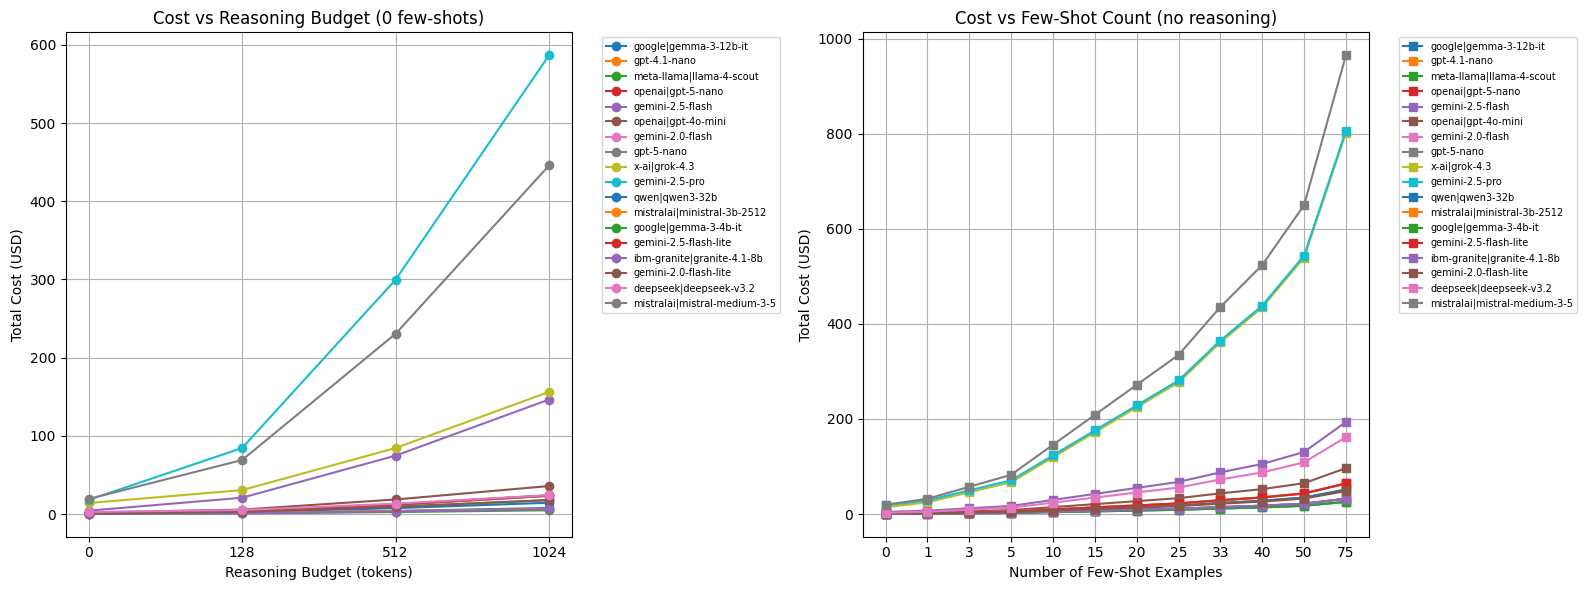

In [7]:
REASONING_BUDGETS = [0, 128, 512, 1024]
FEW_SHOT_CONFIGS = [0, 1, 3, 5, 10, 15, 20, 25, 33, 40, 50, 75]
TOKENS_PER_SHOT = 150

cost_matrix = build_cost_comparison_table(
    models=selected_models,
    usage=base_usage,
    size="reduced",
    n_versions=1,
    n_prompts=2,
    reasoning_budgets=REASONING_BUDGETS,
    few_shot_configs=FEW_SHOT_CONFIGS,
    tokens_per_shot=TOKENS_PER_SHOT,
)

print(f"Cost matrix shape: {cost_matrix.shape}")
# display(cost_matrix.style.format({c: "${:.4f}" for c in cost_matrix.columns if c not in ["Model", "Config"]}))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

no_shots = cost_matrix[cost_matrix["Config"].str.contains("shots=0")]
for model_name in selected_models:
    model_data = no_shots[no_shots["Model"] == model_name]
    if not model_data.empty:
        labels = [c.split(",")[0].replace("reason=", "") for c in model_data["Config"]]
        axes[0].plot(labels, model_data["Total"], marker="o", label=model_name)

axes[0].set_xlabel("Reasoning Budget (tokens)")
axes[0].set_ylabel("Total Cost (USD)")
axes[0].set_title("Cost vs Reasoning Budget (0 few-shots)")
axes[0].legend(bbox_to_anchor=(1.05, 1), fontsize=7)
axes[0].grid(True)

no_reasoning = cost_matrix[cost_matrix["Config"].str.contains("reason=0")]
for model_name in selected_models:
    model_data = no_reasoning[no_reasoning["Model"] == model_name]
    if not model_data.empty:
        labels = [c.split(",")[1].replace("shots=", "").strip() for c in model_data["Config"]]
        axes[1].plot(labels, model_data["Total"], marker="s", label=model_name)

axes[1].set_xlabel("Number of Few-Shot Examples")
axes[1].set_ylabel("Total Cost (USD)")
axes[1].set_title("Cost vs Few-Shot Count (no reasoning)")
axes[1].legend(bbox_to_anchor=(1.05, 1), fontsize=7)
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [8]:
ANALYSIS_MODEL_NAME = "gemini-2.5-flash"
analysis_model = all_model_metadata.get(ANALYSIS_MODEL_NAME)
if analysis_model is None:
    print(f"Model '{ANALYSIS_MODEL_NAME}' not found, using first available")
    ANALYSIS_MODEL_NAME = next(iter(selected_models))
    analysis_model = selected_models[ANALYSIS_MODEL_NAME]

print(f"=== Per-dataset cost breakdown: {ANALYSIS_MODEL_NAME} ===\n")
for dataset_name, subsets in DATASET_SUBSETS_MAP.items():
    costs = estimate_dataset_cost(analysis_model, dataset_name, base_usage, size="reduced", n_versions=1)
    print(f"  {dataset_name}:")
    for subset, cost in costs.items():
        n_pairs = get_num_pairs(subset, "reduced")
        print(f"    {subset:30s} ({n_pairs:5d} pairs) -> {format_cost(cost * 2)} (2 prompts)")
    total = sum(costs.values()) * 2
    print(f"    {'TOTAL':30s} -> {format_cost(total)}")
    print()

full_costs = estimate_full_eval_cost(analysis_model, base_usage, size="reduced", n_versions=1, n_prompts=2)
print(f"Full evaluation total: {format_cost(sum(full_costs.values()))}")

full_costs_10v = estimate_full_eval_cost(analysis_model, base_usage, size="reduced", n_versions=10, n_prompts=2)
print(f"Full evaluation total (10 versions): {format_cost(sum(full_costs_10v.values()))}")

=== Per-dataset cost breakdown: gemini-2.5-flash ===

  bioml-2024:
    ncit-doid                      ( 3281 pairs) -> $0.519 (2 prompts)
    omim-ordo                      ( 2606 pairs) -> $0.412 (2 prompts)
    snomed-fma.body                ( 5080 pairs) -> $0.804 (2 prompts)
    snomed-ncit.neoplas            ( 2664 pairs) -> $0.421 (2 prompts)
    snomed-ncit.pharm              ( 4063 pairs) -> $0.643 (2 prompts)
    TOTAL                          -> $2.80

  largebio:
    fma-nci                        ( 1770 pairs) -> $0.280 (2 prompts)
    fma-snomed                     ( 2904 pairs) -> $0.459 (2 prompts)
    snomed-nci                     ( 5144 pairs) -> $0.814 (2 prompts)
    TOTAL                          -> $1.55

  anatomy:
    human-mouse                    (  508 pairs) -> $0.080 (2 prompts)
    TOTAL                          -> $0.080

Full evaluation total: $4.43
Full evaluation total (10 versions): $44.33


In [ ]:
# Collect real token-usage stats and build the per-(model, experiment) cost table
usage_stats_df = collect_all_usage_stats()
usage_stats_df = usage_stats_df.dropna(subset=["mean_input_tokens", "mean_output_tokens"])
print(f"Collected usage stats: {len(usage_stats_df)} rows")

all_tasks = get_all_tasks()
real_usage_cost_df = build_real_usage_cost_table(usage_stats_df, all_model_metadata, tasks=all_tasks, n_prompts=2)
display(real_usage_cost_df[["Model", "Experiment", *all_tasks, "Total", "real_tasks", "scaled_tasks"]].head(15))

In [ ]:
# Cost heatmap per (model, experiment) — (R)=real usage, (S)=scaled from other tasks
if not real_usage_cost_df.empty:
    heatmap_df = real_usage_cost_df.copy()
    heatmap_df["Label"] = heatmap_df["Model"] + " | " + heatmap_df["Experiment"]
    heatmap_df = heatmap_df.set_index("Label")
    cost_data = heatmap_df[[*all_tasks, "Total"]].astype(float).sort_values("Total")
    source_data = heatmap_df[[f"{t}_source" for t in all_tasks]].copy()
    source_data.columns = all_tasks
    source_data = source_data.loc[cost_data.index]
    cost_heatmap(cost_data, all_tasks, source_data=source_data,
                 title="Cost per (model, experiment) — R=real, S=scaled")

# Avg retries / failures / error-rate per (model, experiment), averaged over tasks & prompts
all_exp_stats_df = collect_all_experiment_stats()
print(f"Collected {len(all_exp_stats_df)} experiment-prompt rows")
agg_map = {
    name: (col, "mean")
    for name, col in [("avg_retries", "perf_mean_num_retries"),
                      ("avg_errors", "perf_num_errors"),
                      ("avg_error_rate", "perf_error_rate")]
    if col in all_exp_stats_df.columns
}
if agg_map:
    retry_agg = all_exp_stats_df.groupby(["model", "exp_name"]).agg(**agg_map).reset_index()
    retry_agg["label"] = retry_agg["exp_name"]
    for ycol, title in [("avg_retries", "Avg retries"), ("avg_errors", "Avg failures"),
                        ("avg_error_rate", "Avg error rate")]:
        if ycol in retry_agg.columns:
            grouped_bar(retry_agg.sort_values(ycol, ascending=False), x="label", y=ycol, color="model",
                        title=f"{title} per (model, experiment)", labels={"label": "Model | Experiment"})

In [ ]:
# Performance vs token-usage / cost scatter plots for human-mouse
metric = "Youden's index"
experiment_stats_df = collect_all_experiment_stats(subsets=["human-mouse"])
scatter_df = experiment_stats_df.dropna(subset=[f"perf_{metric}"]).copy()
scatter_df["label"] = scatter_df["model"] + " | " + scatter_df["exp_name"]
scatter_df = add_experiment_costs(scatter_df, all_model_metadata, subset="human-mouse")
print(f"Scatter data: {len(scatter_df)} rows")

scatter_specs = [
    ("mean_proc_time", "Avg Processing Time (s)"),
    ("mean_input_tokens", "Avg Input Tokens"),
    ("mean_output_tokens", "Avg Output Tokens"),
    ("mean_output_reasoning_tokens", "Avg Reasoning Tokens"),
    ("cost_per_pair", "Cost per Pair (USD)"),
    ("total_cost", "Total Cost (USD)"),
]
for x_col, x_label in scatter_specs:
    if x_col not in scatter_df.columns:
        continue
    data = scatter_df.dropna(subset=[x_col])
    if data.empty or (data[x_col] == 0).all():
        continue
    scatter(data, x=x_col, y=f"perf_{metric}", color="model", symbol="prompt",
            hover_data=["exp_name", "model", "prompt"],
            title=f"{metric} vs {x_label} (human-mouse, reduced)",
            labels={x_col: x_label, f"perf_{metric}": metric})

In [ ]:
# Token-usage distribution and cost-component breakdown per (model, experiment)
token_cols = ["mean_input_tokens", "mean_output_tokens", "mean_input_cached_tokens", "mean_output_reasoning_tokens"]
available = [c for c in token_cols if c in usage_stats_df.columns]
agg_cols = available + (["mean_proc_time"] if "mean_proc_time" in usage_stats_df.columns else [])
token_agg = usage_stats_df.groupby(["model", "exp_name"])[agg_cols].mean().reset_index()
token_agg["label"] = token_agg["exp_name"]

rename_map = {
    "mean_input_tokens": "Input Tokens", "mean_output_tokens": "Output Tokens",
    "mean_input_cached_tokens": "Cached Input Tokens", "mean_output_reasoning_tokens": "Reasoning Tokens",
}
plot_cols = [rename_map[c] for c in available]
stacked_bar(token_agg.sort_values("mean_input_tokens", ascending=False).rename(columns=rename_map),
            x="label", y_cols=plot_cols, title="Average token usage per (model, experiment)",
            labels={"value": "Tokens", "variable": "Token Type", "label": "Model | Experiment"})

cost_comp_df = compute_cost_components(token_agg, all_model_metadata, label_col="label")
if not cost_comp_df.empty:
    cost_comp_df = cost_comp_df.sort_values("Total Cost", ascending=False)
    stacked_bar(cost_comp_df, x="label",
                y_cols=["Input Cost", "Cached Input Cost", "Output Cost", "Reasoning Cost"],
                title="Cost component distribution per pair per (model, experiment)",
                labels={"value": "Cost (USD)", "variable": "Cost Component", "label": "Model | Experiment"},
                plot_kwargs={"tickangle": -90})

In [ ]:
# Detailed token breakdown: percentages, reasoning ratio, cache utilisation, time vs tokens
bd = add_token_breakdown_pct(token_agg)
summary_cols = ["label", "model", "mean_input_tokens", "mean_output_tokens", "total_tokens",
                "input_pct", "output_pct", "cache_hit_pct", "reasoning_pct"]
display(bd[summary_cols].sort_values("total_tokens", ascending=False).head(15))

stacked_bar(bd.sort_values("reasoning_pct", ascending=False), x="label", y_cols=["input_pct", "output_pct"],
            title="Input vs Output token % per experiment",
            labels={"value": "Percentage (%)", "variable": "Token Type", "label": "Experiment"},
            plot_kwargs={"tickangle": -45, "color_discrete_map": {"input_pct": "#636EFA", "output_pct": "#EF553B"}})

reasoning_df = bd[bd["reasoning_pct"] > 0]
if not reasoning_df.empty:
    scatter(reasoning_df, x="mean_output_tokens", y="reasoning_pct", color="model", size="total_tokens",
            hover_data=["label", "cache_hit_pct"], title="Reasoning token ratio vs output tokens",
            labels={"mean_output_tokens": "Avg Output Tokens", "reasoning_pct": "Reasoning % of Output"})

cache_df = bd[bd["cache_hit_pct"] > 0]
if not cache_df.empty:
    grouped_bar(cache_df.sort_values("cache_hit_pct", ascending=False), x="label", y="cache_hit_pct", color="model",
                title="Cache hit rate per experiment", labels={"cache_hit_pct": "Cache Hit %", "label": "Experiment"},
                plot_kwargs={"tickangle": -45})

if "mean_proc_time" in bd.columns:
    time_df = bd[bd["mean_proc_time"] > 0]
    if not time_df.empty:
        scatter(time_df, x="total_tokens", y="mean_proc_time", color="model", hover_data=["label", "reasoning_pct"],
                title="Processing time vs total tokens per pair",
                labels={"total_tokens": "Total Tokens", "mean_proc_time": "Avg Processing Time (s)"})

In [ ]:
# Estimated cost-per-task heatmap (base config) and save the full cost tables
wide_cost = build_cost_comparison_table(
    models=all_model_metadata, usage=base_usage, size="reduced", n_versions=1, n_prompts=2,
)
heatmap_data = wide_cost[wide_cost["Config"] == "base"].set_index("Experiment")
task_cols = [c for c in heatmap_data.columns if c in get_all_tasks()]
heatmap_data = heatmap_data[[*task_cols, "Total"]].astype(float).sort_values("Total")
cost_heatmap_mpl(heatmap_data, title="Estimated cost per task (USD) — reduced set, 2 prompts, 1 version")

save_path = METRICS_DIR / "estimations"
save_path.mkdir(parents=True, exist_ok=True)
wide_cost.to_csv(save_path / "cost_estimates_all_models.csv", index=False)
pricing_summary.to_csv(save_path / "model_pricing_summary.csv")
print(f"Saved cost estimates to {save_path}")